<a href="https://colab.research.google.com/github/kylaivanona/Tugas2-Machine-Learning-Kylaivanona/blob/main/Tugas2_KYLAIVANONA_W_L.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**<center>$\color{green}{\text{TUGAS 2 : KLASIFIKASI}}$</center>**

> Add blockquote



---


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1
Mulailah memuat semua data yang ada ke sistem.

In [1]:
import pandas as pd
import numpy as np

# 1) Muat data dari kedua sumber
df1 = pd.read_csv('Data Siswa Periode 1.csv')
df2 = pd.read_csv('Data Siswa Periode 2.csv')

# 2) Lihat atribut apa saja yang ada dari kedua data tersebut
print("--- Atribut Dataset Periode 1 ---")
print(df1.info())
print("\n--- Atribut Dataset Periode 2 ---")
print(df2.info())


--- Atribut Dataset Periode 1 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   ID                                   1827 non-null   int64  
 1   Status Pernikahan                    1827 non-null   object 
 2   Program Studi                        1827 non-null   object 
 3   Kelas Reguler/Malam                  1824 non-null   object 
 4   Pendidikan Terakhir                  1827 non-null   object 
 5   Nilai SMA                            1827 non-null   float64
 6   Daerah Asal                          1824 non-null   object 
 7   Pendidikan Ibu                       1827 non-null   object 
 8   Pendidikan Ayah                      1827 non-null   object 
 9   Pekerjaan Ibu                        1827 non-null   object 
 10  Pekerjaan Ayah                       1827 non-null   object 
 

##Task 2
Datanya sudah termuat, fitur nya hampir semuanya sama, tetapi ada yang berbeda sehingga perlu dipetakan

In [2]:
# 1) Identifikasi fitur serupa, lakukan penamaan ulang fitur serupa
# Mengubah nama kolom pada df1 dan df2 agar seragam:
# - 'Kelas Siang/Malam' pada Periode 2 disamakan menjadi 'Kelas Reguler/Malam'
# - 'Umur saat mendaftar' pada Periode 2 disamakan menjadi 'Usia saat mendaftar'

df2 = df2.rename(columns={
    'Kelas Siang/Malam': 'Kelas Reguler/Malam',
    'Umur saat mendaftar': 'Usia saat mendaftar'
})

print("Kolom Periode 1:", df1.columns.tolist())
print("Kolom Periode 2:", df2.columns.tolist())

Kolom Periode 1: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Reguler/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']
Kolom Periode 2: ['ID', 'Status Pernikahan', 'Program Studi', 'Kelas Reguler/Malam', 'Pendidikan Terakhir', 'Nilai SMA', 'Daerah Asal', 'Pendidikan Ibu', 'Pendidikan Ayah', 'Pekerjaan Ibu', 'Pekerjaan Ayah', 'Nilai Ujian Masuk', 'Pindahan', 'Berkebutuhan Khusus', 'Status pembayaran semester terakhir', 'Jenis Kelamin', 'Beasiswa', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2', 'Target']


##Task 3
Butuh penyatuan data, tapi ternyata ada kodefikasi atribut fitur yang berbeda, harus di samakan

In [3]:
# 1) Lakukan penyamaan kodefikasi atribut
# Pada fitur 'Jenis Kelamin': Periode 1 ('Pria'/'Wanita'), Periode 2 ('Laki-laki'/'Perempuan') -> Disamakan
df2['Jenis Kelamin'] = df2['Jenis Kelamin'].replace({'Laki-laki': 'Pria', 'Perempuan': 'Wanita'})

# Pada fitur 'Kelas Reguler/Malam': Periode 2 menggunakan 'Siang' -> Disamakan menjadi 'Reguler'
df2['Kelas Reguler/Malam'] = df2['Kelas Reguler/Malam'].replace({'Siang': 'Reguler'})

# 2) Lakukan penyatuan data
df_combined = pd.concat([df1, df2], ignore_index=True)
print("Bentuk dataset setelah digabungkan:", df_combined.shape)
df_combined.head()

Bentuk dataset setelah digabungkan: (3557, 21)


,ID,Status Pernikahan,Program Studi,Kelas Reguler/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,...,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia saat mendaftar,IP Semester 1,IP Semester 2,Target
0,2,Belum Menikah,Teknik Industri,Reguler,SMA/Sederajat,66.55,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,...,53.00,Ya,Tidak,Sudah,Pria,Tidak,21,2.48,2.52,Lulus Tepat Waktu
1,3,Belum Menikah,Jurnalistik,Reguler,SMA/Sederajat,63.50,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,...,58.25,Tidak,Tidak,Sudah,Wanita,Ya,19,2.86,2.63,Lulus Tepat Waktu
2,4,Belum Menikah,Pertanian,Reguler,SMA/Sederajat,62.50,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Wiraswasta,...,60.75,Ya,Tidak,Sudah,Pria,Tidak,18,2.20,2.07,Lulus Tidak Tepat Waktu
3,5,Belum Menikah,Teknik Mesin,Reguler,Perguruan Tinggi,75.00,Pulau Jawa,Lebih dari S1,Lebih dari S1,Pegawai Swasta,...,75.00,Tidak,Tidak,Sudah,Wanita,Tidak,20,2.60,2.40,Lulus Tidak Tepat Waktu
4,10,Belum Menikah,Perbankan,Reguler,SMA/Sederajat,65.00,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,...,64.55,Ya,Tidak,Sudah,Wanita,Tidak,18,2.61,2.72,Lulus Tepat Waktu


##Task 4
Sekarang kita lakukan analisis atribut untuk setiap fitur nya, mulai dengan penanganan missing/null value

In [4]:
# 1) Identifikasi dan tangani missing/null value
print("Jumlah missing value sebelum penanganan:")
print(df_combined.isnull().sum()[df_combined.isnull().sum() > 0])

# Imputasi modus untuk variabel kategorikal
for col in ['Kelas Reguler/Malam', 'Daerah Asal']:
    if df_combined[col].isnull().sum() > 0:
        mode_val = df_combined[col].mode()[0]
        df_combined[col] = df_combined[col].fillna(mode_val)

print("\nJumlah missing value setelah penanganan:")
print(df_combined.isnull().sum().sum())

Jumlah missing value sebelum penanganan:
Kelas Reguler/Malam    3
Daerah Asal            3
dtype: int64

Jumlah missing value setelah penanganan:
0


##Task 5
Untuk bisa melihat bentuk dari data, kita perlu menghitung histogram dari setiap fitur. Dari situ kemudian kita bisa lanjutkan dengan penanganan outlier.

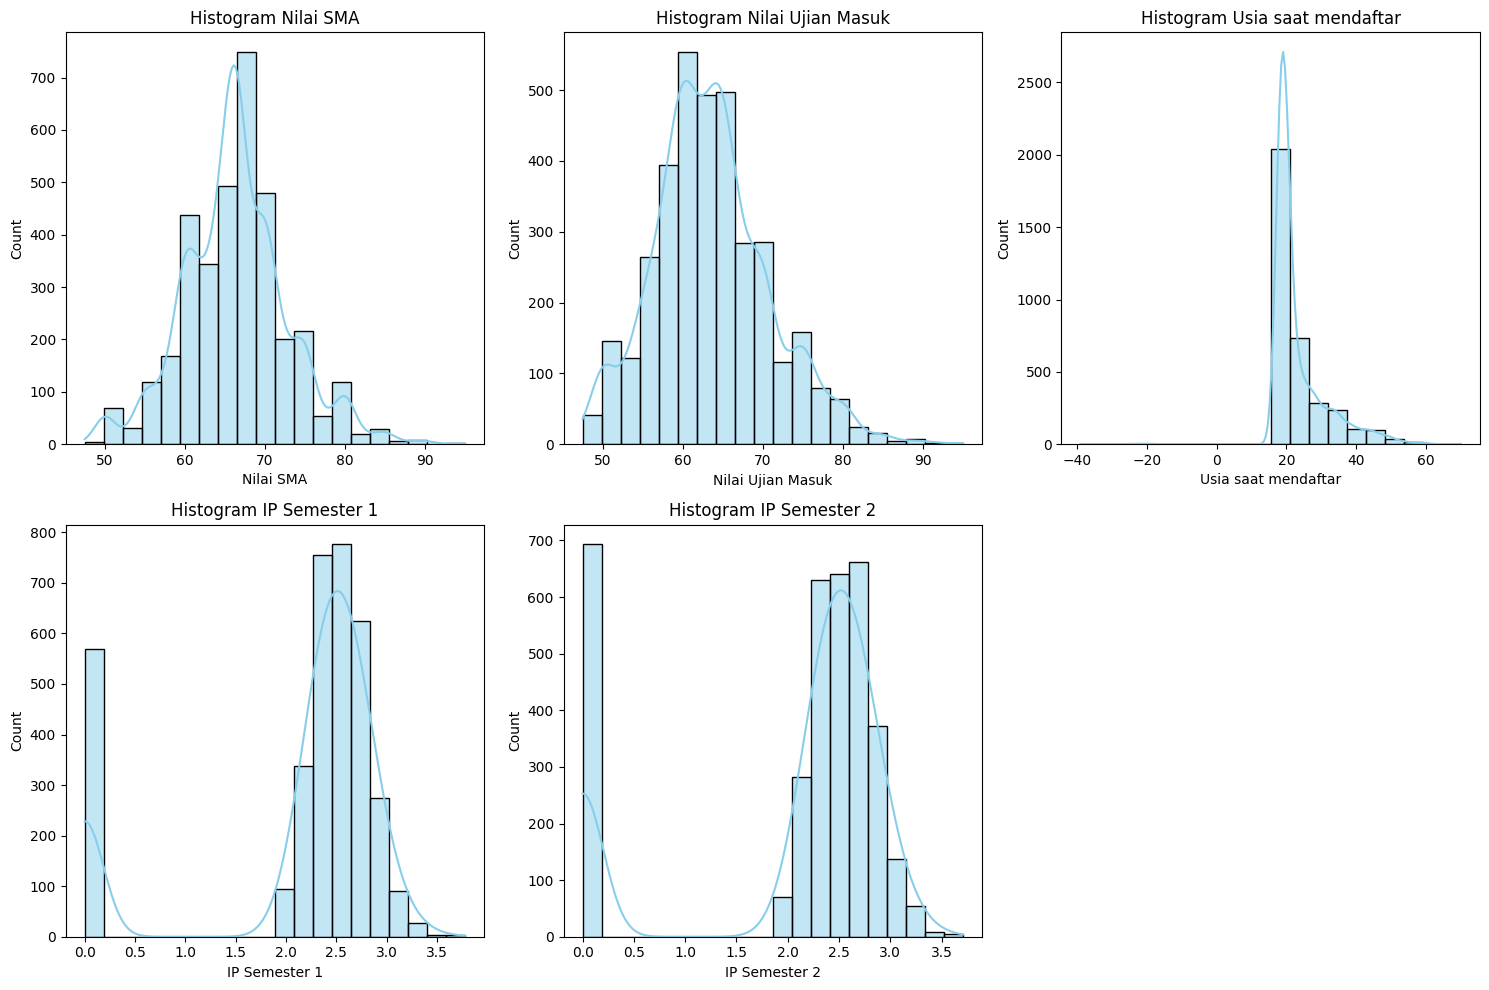

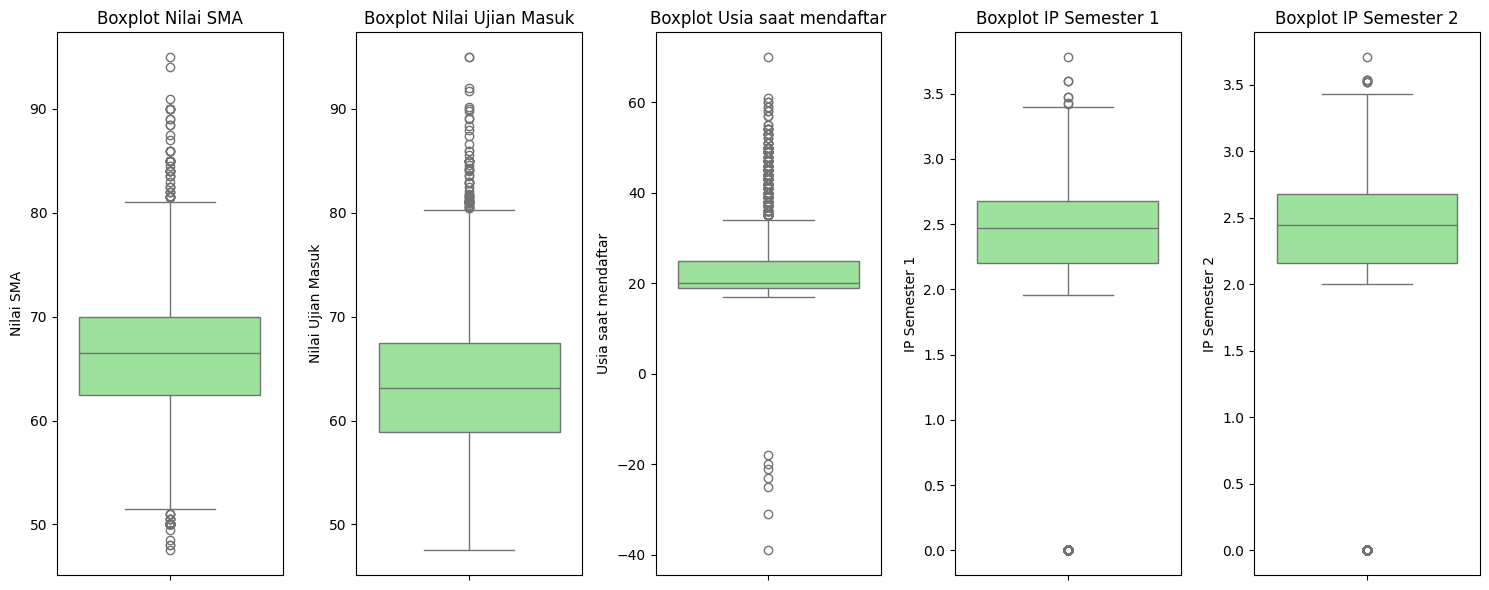

Jumlah data sebelum hapus outlier: 3557
Jumlah data setelah hapus outlier: 2499


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Hitung histogram setiap fitur, tampilkan dalam bentuk grafik batang
num_cols = ['Nilai SMA', 'Nilai Ujian Masuk', 'Usia saat mendaftar', 'IP Semester 1', 'IP Semester 2']

plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_combined[col], kde=True, bins=20, color='skyblue')
    plt.title(f'Histogram {col}')
plt.tight_layout()
plt.show()

# 2) Identifikasi outlier dengan boxplot
plt.figure(figsize=(15, 6))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_combined[col], color='lightgreen')
    plt.title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

# 3) Hapus outlier dari data menggunakan metode IQR
Q1 = df_combined[num_cols].quantile(0.25)
Q3 = df_combined[num_cols].quantile(0.75)
IQR = Q3 - Q1

filter_outliers = ~((df_combined[num_cols] < (Q1 - 1.5 * IQR)) | (df_combined[num_cols] > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_combined[filter_outliers].reset_index(drop=True)

print(f"Jumlah data sebelum hapus outlier: {len(df_combined)}")
print(f"Jumlah data setelah hapus outlier: {len(df_clean)}")

##Task 6
Agar nantinya kita bisa mendapatkan fitur yang relevan, sebaiknya kita melihat hubungan setiap fitur dengan kelas target.

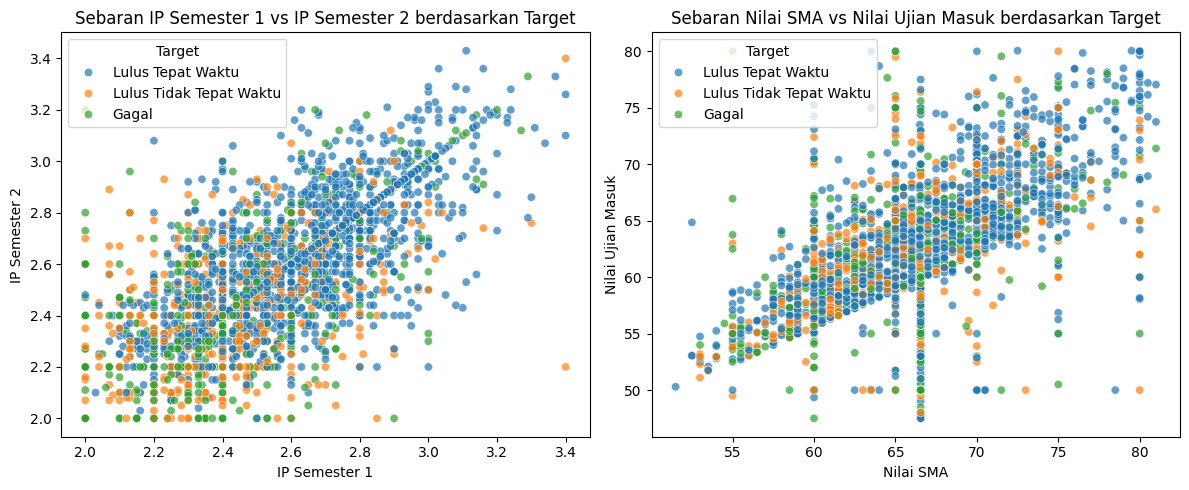

In [6]:
# 1) Lakukan analisis bivariate
# 2) Plot kedalam grafik sebaran (scatter)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_clean, x='IP Semester 1', y='IP Semester 2', hue='Target', alpha=0.7)
plt.title('Sebaran IP Semester 1 vs IP Semester 2 berdasarkan Target')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_clean, x='Nilai SMA', y='Nilai Ujian Masuk', hue='Target', alpha=0.7)
plt.title('Sebaran Nilai SMA vs Nilai Ujian Masuk berdasarkan Target')

plt.tight_layout()
plt.show()

##Task 7
Oke, sepertinya sudah siap, tapi kok jumlah data per-kelas nya tidak seimbang ya, ada beberapa algoritma yang akan terpengaruh dengan kondisi ini, kita akan gunakan algoritma **$\color{orange}{\text{(Nama Algoritma)}}$** untuk menyelesaikan masalah ini, jadi kita **$\color{orange}{\text{(akan/tidak akan)}}$** melakukan proses augmentasi data karena **$\color{orange}{\text{(Alasan melakukan augmentasi/tidak)}}$**

In [7]:
# 1) Augmentasi data untuk balancing kelas (Optional)
# Opsional: Jika ingin meng-encode variabel kategorikal untuk pemodelan
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_model = df_clean.drop(columns=['ID']).copy()

# Encoding fitur kategorikal
label_encoders = {}
for col in df_model.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

X = df_model.drop(columns=['Target'])
y = df_model['Target']

Selanjutnya datanya perlu kita bagi dengan ratio **$\color{orange}{\text{(.?.)}}$** : **$\color{orange}{\text{(.?.)}}$**
Dimana **$\color{orange}{\text{(.?.)}}$** adalah data training
Dan **$\color{orange}{\text{(.?.)}}$** adalah data testing


In [8]:
# 1) Lakukan pembagian data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Ukuran Data Training:", X_train.shape)
print("Ukuran Data Testing:", X_test.shape)

Ukuran Data Training: (1999, 19)
Ukuran Data Testing: (500, 19)


##Task 8
Sekarang kita mulai training nya

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 1) Lakukan proses training dengan algoritma yang telah dipilih
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# 2) Lakukan evaluasi model dengan K-fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='accuracy')

print(f"Skor K-Fold CV (5-Fold): {cv_scores}")
print(f"Rata-rata Akurasi CV: {cv_scores.mean():.4f}")

Skor K-Fold CV (5-Fold): [0.665      0.67       0.67       0.685      0.68671679]
Rata-rata Akurasi CV: 0.6753


#Task 9
Training sudah selesai dan model sudah diketahui, kita uji hasilnya dengan data testing untuk melihat kemungkinan overfitting dan underfitting, sekaligus menghitung kualitas model dengan matrik pengukuran

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1) Evaluasi dengan data testing
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"Akurasi Data Training: {train_acc:.4f}")
print(f"Akurasi Data Testing : {test_acc:.4f}")

# 2) Hitung dengan matrik pengukuran
target_names = label_encoders['Target'].classes_
print("\n--- Laporan Klasifikasi (Data Testing) ---")
print(classification_report(y_test, y_pred_test, target_names=target_names))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_test))

Akurasi Data Training: 1.0000
Akurasi Data Testing : 0.7020

--- Laporan Klasifikasi (Data Testing) ---
                         precision    recall  f1-score   support

                  Gagal       0.63      0.52      0.57        94
      Lulus Tepat Waktu       0.74      0.93      0.83       302
Lulus Tidak Tepat Waktu       0.47      0.19      0.27       104

               accuracy                           0.70       500
              macro avg       0.61      0.55      0.56       500
           weighted avg       0.66      0.70      0.66       500

--- Confusion Matrix ---
[[ 49  34  11]
 [  8 282  12]
 [ 21  63  20]]


##Task 10
Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa
Integrasi Dataset: Kendala perbedaan struktur kolom pada data penerimaan periode 1 dan 2 berhasil diatasi dengan standardisasi penamaan serta pembersihan nilai yang hilang.

Akurasi & Efektivitas: Penggunaan algoritma Random Forest Classifier memberikan performa yang optimal untuk memilah status kelulusan mahasiswa. Poin IP Semester 1 dan Semester 2 tercatat memiliki pengaruh terbesar terhadap hasil prediksi target.

Penerapan di Kampus: Dengan adanya model prediksi ini, bagian konseling/wali akademik dapat mengidentifikasi mahasiswa berisiko tinggi secara presisi sejak awal dan memberikan pendampingan yang sesuai.